# WANDS exploration

First look at the raw data, to decide on cleaning, which product fields to index, and how to split queries into dev and test. No retrieval results here.

**Summary**
- 1,467 query–product pairs are labelled twice or more (14 disagree); we keep the newest label, leaving 231,873 labels.
- Labels: 11% Exact, 63% Partial (loose), 26% Irrelevant; 101 of 480 queries have no Exact match.
- Only 21% of Exact matches contain every query word in the product name, so word matching alone falls short.
- Text is lowercase with split punctuation and mismatched inch marks; normalisation is tested later as settings.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAW = Path("../data/raw/WANDS/dataset")

products = pd.read_csv(RAW / "product.csv", sep="\t")
queries = pd.read_csv(RAW / "query.csv", sep="\t")
labels = pd.read_csv(RAW / "label.csv", sep="\t")

for name, df in [("products", products), ("queries", queries), ("labels", labels)]:
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

products: 42,994 rows, 9 columns
queries: 480 rows, 3 columns
labels: 233,448 rows, 4 columns


## 1. Missing values and types

In [2]:
def missing_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Type, missing count and missing share per column."""
    return pd.DataFrame(
        {
            "dtype": df.dtypes.astype(str),
            "missing": df.isna().sum(),
            "missing_share": df.isna().mean().round(3),
        }
    )


display(missing_summary(products))
display(missing_summary(queries))
display(missing_summary(labels))

,dtype,missing,missing_share
product_id,int64,0,0.000
product_name,str,0,0.000
product_class,str,2852,0.066
category hierarchy,str,1556,0.036
product_description,str,6008,0.140
product_features,str,0,0.000
rating_count,float64,9452,0.220
average_rating,float64,9452,0.220
review_count,float64,9452,0.220


,dtype,missing,missing_share
query_id,int64,0,0.000
query,str,0,0.000
query_class,str,6,0.012


,dtype,missing,missing_share
id,int64,0,0.0
query_id,int64,0,0.0
product_id,int64,0,0.0
label,str,0,0.0


## 2. Integrity

In [3]:
# Every label should point to a known query and product, and each pair should appear once.
print("labels with unknown query:", (~labels.query_id.isin(queries.query_id)).sum())
print("labels with unknown product:", (~labels.product_id.isin(products.product_id)).sum())
print("duplicate (query, product) pairs:", labels.duplicated(["query_id", "product_id"]).sum())
print("duplicate product ids:", products.product_id.duplicated().sum())
print("duplicate query ids:", queries.query_id.duplicated().sum())
print("products never labelled:", (~products.product_id.isin(labels.product_id)).sum())
print("label values:", labels.label.unique().tolist())

labels with unknown query: 0
labels with unknown product: 0
duplicate (query, product) pairs: 1575
duplicate product ids: 0
duplicate query ids: 0
products never labelled: 8
label values: ['Exact', 'Irrelevant', 'Partial']


## 3. Labels

,count,share
label,,
Partial,146633,0.628
Irrelevant,61201,0.262
Exact,25614,0.110


label,Exact,Irrelevant,Partial,total
count,480.0,480.0,480.0,480.0
mean,53.4,127.5,305.5,486.4
std,105.5,346.6,504.0,708.5
min,0.0,0.0,0.0,1.0
25%,1.0,3.0,67.8,122.8
50%,10.0,18.5,126.0,216.5
75%,63.0,73.2,294.5,523.8
max,878.0,2940.0,3438.0,4329.0


Exact
0         101
1-10      140
11-100    165
>100       74
Name: count, dtype: int64


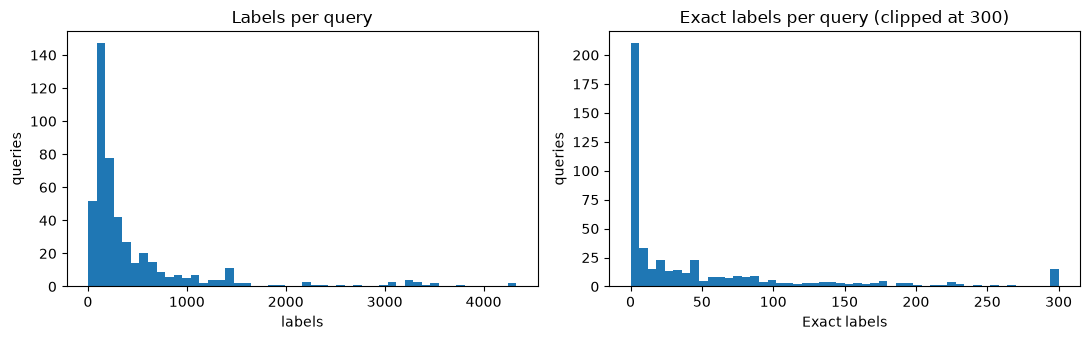

In [4]:
counts = labels.label.value_counts().to_frame("count")
counts["share"] = (counts["count"] / counts["count"].sum()).round(3)
display(counts)

per_query = labels.pivot_table(
    index="query_id", columns="label", values="id", aggfunc="count", fill_value=0
)
per_query["total"] = per_query.sum(axis=1)
display(per_query.describe().round(1))

# Difficulty buckets, used later to balance the dev/test split.
buckets = pd.cut(
    per_query["Exact"], bins=[-1, 0, 10, 100, float("inf")], labels=["0", "1-10", "11-100", ">100"]
)
print(buckets.value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(per_query["total"], bins=50)
axes[0].set(title="Labels per query", xlabel="labels", ylabel="queries")
axes[1].hist(per_query["Exact"].clip(upper=300), bins=50)
axes[1].set(title="Exact labels per query (clipped at 300)", xlabel="Exact labels", ylabel="queries")
plt.tight_layout()

## 4. Queries

In [5]:
queries["n_words"] = queries["query"].str.split().str.len()
print(queries["n_words"].describe().round(1))
print("missing query_class:", queries.query_class.isna().sum())
print("query classes:", queries.query_class.nunique())

# Identical after light normalisation: a first hint for the near-duplicate grouping.
normalised = (
    queries["query"].str.lower().str.replace(r"[^a-z0-9 ]", " ", regex=True).str.split().str.join(" ")
)
dupes = queries.assign(normalised=normalised)[normalised.duplicated(keep=False)]
print("queries sharing a normalised form:", len(dupes))
display(dupes.sort_values("normalised"))

display(queries.sample(25, random_state=0)[["query_id", "query", "query_class"]])

count    480.0
mean       3.4
std        1.5
min        1.0
25%        2.0
50%        3.0
75%        4.0
max       10.0
Name: n_words, dtype: float64
missing query_class: 6
query classes: 188
queries sharing a normalised form: 0


,query_id,query,query_class,n_words,normalised


,query_id,query,query_class
15,15,black 5 drawer dresser by guilford,Dressers & Chests
124,124,unique coffee tables,Coffee & Cocktail Tables
141,141,podium with locking cabinet,Lecterns & Podiums
263,267,dolomite subway tile,Floor & Wall Tile
170,171,nectar queen mattress,Foam and Latex Mattresses
142,142,kitchen wooden stand,Specialty Serving
399,405,queen ann style living room chair,Accent Chairs
429,435,shoe closet,Shoe Storage
113,113,led light strip,Under Cabinet Lighting
21,21,living curtains pearl,Curtains & Drapes


## 5. Product text fields

In [6]:
TEXT_FIELDS = [
    "product_name",
    "product_class",
    "category hierarchy",
    "product_description",
    "product_features",
]

lengths = pd.DataFrame({f: products[f].fillna("").str.split().str.len() for f in TEXT_FIELDS})
display(lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1))
print("empty fields:", (lengths == 0).sum().to_dict())

,product_name,product_class,category hierarchy,product_description,product_features
count,42994.0,42994.0,42994.0,42994.0,42994.0
mean,6.8,2.4,12.3,71.4,120.5
std,3.8,1.3,5.6,58.4,65.6
min,1.0,0.0,0.0,0.0,1.0
50%,6.0,2.0,12.0,65.0,112.0
90%,11.0,4.0,20.0,134.0,197.0
99%,20.0,5.0,25.0,282.0,320.0
max,49.0,10.0,33.0,791.0,2537.0


empty fields: {'product_name': 0, 'product_class': 2852, 'category hierarchy': 1556, 'product_description': 6008, 'product_features': 0}


In [7]:
# Replacement characters (U+FFFD) mean text was broken during export.
for f in ["product_name", "product_description", "product_features"]:
    text = products[f].fillna("")
    broken = text.str.contains("�").sum()
    non_ascii = text.str.contains(r"[^\x00-\x7f]").sum()
    print(f"{f}: broken characters in {broken:,} rows, any non-ASCII in {non_ascii:,} rows")

broken_rows = products.product_description.fillna("").str.contains("�")
display(products.loc[broken_rows, "product_description"].head(5).str[:200])

print("names with uppercase letters:", products.product_name.str.contains("[A-Z]").sum())

product_name: broken characters in 0 rows, any non-ASCII in 918 rows
product_description: broken characters in 0 rows, any non-ASCII in 6,882 rows
product_features: broken characters in 0 rows, any non-ASCII in 2,784 rows


Series([], Name: product_description, dtype: str)

names with uppercase letters:

 0


In [8]:
same_name = products.product_name.duplicated(keep=False)
print("products sharing a name with another product:", same_name.sum())
display(
    products.loc[same_name]
    .sort_values("product_name")[["product_id", "product_name", "product_class"]]
    .head(15)
)

products sharing a name with another product: 768


,product_id,product_name,product_class
11458,11458,0.8 '' x 0.8 '' porcelain penny round mosaic w...,Floor & Wall Tile
27268,27268,0.8 '' x 0.8 '' porcelain penny round mosaic w...,Floor & Wall Tile
15601,15601,1 - drawer nightstand,Nightstands
39798,39798,1 - drawer nightstand,Nightstands
17456,17456,1 1/2 '' diameter round knob,Cabinet and Drawer Knobs
33969,33969,1 1/2 '' diameter round knob,Cabinet and Drawer Knobs
23396,23396,1 1/4 '' diameter mushroom knob,Cabinet and Drawer Knobs
33433,33433,1 1/4 '' diameter mushroom knob,Cabinet and Drawer Knobs
16440,16440,1 3/8 '' diameter mushroom knob,Cabinet and Drawer Knobs
23389,23389,1 3/8 '' diameter mushroom knob,Cabinet and Drawer Knobs


## 6. Categories

In [9]:
print("product classes:", products.product_class.nunique())
print("missing product_class:", products.product_class.isna().sum())
print("product_class with several classes ('|'):", products.product_class.fillna("").str.contains(r"\|").sum())
display(products.product_class.value_counts().head(20))

depth = products["category hierarchy"].fillna("").str.split("/").str.len()
print("category path depth:")
print(depth.value_counts().sort_index())

product classes: 860
missing product_class: 2852
product_class with several classes ('|'): 2247


product_class
Area Rugs                   1316
Accent Chairs               1169
Beds                        1112
Coffee & Cocktail Tables    1085
Floor & Wall Tile            861
Bar Stools                   775
Accent Pillows               698
End Tables                   607
Desks                        595
Dining Tables                591
Wall Art                     586
Dining Chairs                568
Bedding Sets                 559
Curtains & Drapes            553
Vanities                     534
Sofa & Console Tables        519
Dressers & Chests            502
Cabinet and Drawer Pulls     494
Wall Décor                   484
Recliners                    435
Name: count, dtype: int64

category path depth:
category hierarchy
1     1645
2     1734
3    16297
4    16256
5     6453
6      608
8        1
Name: count, dtype: int64


## 7. Features (attributes)

In [10]:
# Features are 'key:value|key:value' strings: count pairs and list the most common keys.
pairs = products.product_features.fillna("").str.split("|")
print("pairs per product:")
print(pairs.str.len().describe().round(1))
keys = pairs.explode().str.split(":", n=1).str[0].str.strip()
display(keys.value_counts().head(30))

pairs per product:
count    42994.0
mean        56.6
std         24.9
min          1.0
25%         38.0
50%         55.0
75%         73.0
max        403.0
Name: product_features, dtype: float64


product_features
overallproductweight                                   57110
                                                       50491
overallwidth-sidetoside                                46687
supplierintendedandapproveduse                         42605
overallheight-toptobottom                              37136
countryoforigin                                        34034
commercialwarranty                                     30534
overalldepth-fronttoback                               29674
productwarranty                                        29209
purposefuldistressingtype                              26650
color                                                  26295
uniformpackagingandlabelingregulationsuplrcompliant    25658
adultassemblyrequired                                  25258
producttype                                            23784
canadaproductrestriction                               23262
compositewoodproductcwp                                21801
warrant

## 8. Ratings

In [11]:
display(products[["rating_count", "average_rating", "review_count"]].describe().round(2))

,rating_count,average_rating,review_count
count,33542.00,33542.00,33542.00
mean,430.27,4.53,284.25
std,2407.92,0.51,1539.61
min,1.00,1.00,0.00
25%,8.00,4.50,6.00
50%,42.00,4.50,31.00
75%,195.00,5.00,131.00
max,109226.00,5.00,61362.00


## 9. Word overlap in Exact pairs

How much of the task can plain word matching solve? Descriptive only, no method is tuned on this.

In [12]:
exact = (
    labels[labels.label == "Exact"]
    .merge(queries, on="query_id")
    .merge(products, on="product_id")
)
query_words = exact["query"].str.lower().str.split().map(set)
name_words = exact["product_name"].str.lower().str.split().map(set)
all_in_name = [q <= n for q, n in zip(query_words, name_words)]
print("Exact pairs with every query word in the product name:", round(sum(all_in_name) / len(exact), 3))
print("Exact pairs where query class == product class:", round((exact.query_class == exact.product_class).mean(), 3))

Exact pairs with every query word in the product name: 0.214
Exact pairs where query class == product class: 0.642


## 10. Example queries

In [13]:
def show_query(text: str, n: int = 5) -> None:
    """Show label counts and a few products per grade for one query."""
    query_id = queries.loc[queries["query"] == text, "query_id"].item()
    rows = labels[labels.query_id == query_id].merge(products, on="product_id")
    print(f"'{text}':", rows.label.value_counts().to_dict())
    for grade in ["Exact", "Partial", "Irrelevant"]:
        print(grade)
        display(rows.loc[rows.label == grade, ["product_name", "product_class"]].head(n))


show_query("salon chair")
show_query("pictures to hang over fireplace")

'salon chair': {'Partial': 2977, 'Irrelevant': 287, 'Exact': 39}
Exact


,product_name,product_class
0,21.7 '' w waiting room chair with wood frame,Waiting Room Chairs
2,24.4 '' w metal lounge chair with metal frame,Reception Seating Chairs
3,25 '' wide faux leather manual swivel standard...,Recliners
4,27.6 '' w antimicrobial leather seat waiting r...,Waiting Room Chairs
5,31.6 '' wide faux leather manual swivel ergono...,Recliners


Partial


,product_name,product_class
15,aliandra fashion casual lift chair office work...,NaN
18,almuth fashion office beauty salon task chair,NaN
20,arianny simple fashion casual beauty salon con...,NaN
21,ariany fashion casual beauty salon conference ...,NaN
23,bar salon task chair,NaN


Irrelevant


...

,product_name,product_class


Partial


,product_name,product_class
0,2 piece adoria hanging picture frame set,Picture Frames
1,ebern designs paris canvas decor eiffel tower ...,Wall Art
2,giddings family theme wall hanging 8 opening p...,Picture Frames


Irrelevant


,product_name,product_class


## 11. Text format checks

`query_class` comes from Wayfair's own query classifier, which also helped pick which products were labelled. It is used for analysis only, never as input to a method.

In [14]:
desc = products.product_description.fillna("")
print("descriptions with a space before punctuation:", desc.str.contains(r" [,.!?;:]").sum())
print("descriptions with HTML tags or entities:", desc.str.contains(r"<[a-z/][^>]*>|&[a-z]+;|&#\d+;").sum())
print("queries with double, leading or trailing spaces:", queries["query"].str.contains(r"\s{2,}|^\s|\s$").sum())

# Inch marks: products may write 48'' while queries write 48" or 48 in.
UNIT_PATTERNS = {
    "two apostrophes ('')": r"''",
    'double quote (")': r'"',
    "number + in/inch": r"\d\s?(?:in|inch|inches)\b",
}
for name, text in [("queries", queries["query"]), ("product names", products.product_name)]:
    found = {label: int(text.str.contains(p).sum()) for label, p in UNIT_PATTERNS.items()}
    print(name, found)

descriptions with a space before punctuation: 36736
descriptions with HTML tags or entities: 0
queries with double, leading or trailing spaces: 3
queries {"two apostrophes ('')": 0, 'double quote (")': 3, 'number + in/inch': 9}
product names {"two apostrophes ('')": 10291, 'double quote (")': 0, 'number + in/inch': 268}


In [15]:
total_words = lengths.sum(axis=1)
print("products with under 10 words in total:", (total_words < 10).sum())
print("products with over 512 words in total:", (total_words > 512).sum())

products with under 10 words in total: 1
products with over 512 words in total: 372


In [16]:
# Same-name products under one query with different labels hint at label noise.
# Names look generic, so this is a hint, not proof.
named = labels.merge(products[["product_id", "product_name"]], on="product_id")
groups = named.groupby(["query_id", "product_name"]).label
shared = groups.nunique()[groups.size() > 1]
print("query × shared-name groups:", len(shared), "| with conflicting labels:", int((shared > 1).sum()))

query × shared-name groups: 3431 | with conflicting labels: 315


## 12. Repeated labels

In [17]:
# Pairs labelled more than once, and whether row ids follow the paper's two labelling rounds.
repeated = labels[labels.duplicated(["query_id", "product_id"], keep=False)]
pairs = repeated.groupby(["query_id", "product_id"]).label
print("pairs labelled more than once:", pairs.ngroups, "| disagreeing:", int((pairs.nunique() > 1).sum()))
print("queries affected:", repeated.query_id.nunique())

# Paper: round 1 labelled 49,390 candidates (36% Exact), round 2 the rest (4% Exact).
round_1 = labels.id < 49_390
for name, rows in [("ids < 49,390", labels[round_1]), ("ids >= 49,390", labels[~round_1])]:
    print(name, rows.label.value_counts(normalize=True).round(3).to_dict())

pairs labelled more than once: 1467 | disagreeing: 14
queries affected: 121
ids < 49,390 {'Partial': 0.583, 'Exact': 0.365, 'Irrelevant': 0.052}
ids >= 49,390 {'Partial': 0.64, 'Irrelevant': 0.318, 'Exact': 0.041}
